In [ ]:
# Google Colab : télécharger les données de cette séance / download this session's data
import os, urllib.request
BASE = "https://raw.githubusercontent.com/Marzoug-Nabil/Nabil/main/academic/teaching/fsci6222/materials/s06/"
for f in ['consommation_energie.csv', 'maisons.csv']:
    os.makedirs('data', exist_ok=True)
    for dst in (f, os.path.join('data', f)):
        if not os.path.exists(dst):
            urllib.request.urlretrieve(BASE + f, dst)


# FSCI 6222 -- Analyse de donnees
# Complement seance 6 : Arbres de decision et Random Forest
## Notebook de demonstration

Universite de Moncton -- Faculte des sciences -- Ete 2026

---

Dans la seance 6, la regression lineaire fonctionnait tres bien parce que la relation entre superficie et prix etait essentiellement lineaire. Ce n'est pas toujours le cas dans la vraie vie : beaucoup de phenomenes presentent des **non-linearites** et des **interactions** que le modele lineaire ne peut pas capturer.

Ce notebook utilise un nouveau dataset (`consommation_energie.csv`) ou la relation est volontairement non-lineaire, pour montrer que :

1. la **regression lineaire echoue** quand les relations ne sont pas lineaires ;
2. un **arbre de decision** capture naturellement les non-linearites ;
3. la **foret aleatoire** ameliore encore les performances ;
4. le **Gradient Boosting** pousse la performance encore plus loin ;
5. on peut **interpreter** ces modeles via l'importance des variables.


## 1. Le contexte : prediction de la consommation electrique d'un batiment

On veut predire la **consommation horaire** d'electricite (en kWh) d'un batiment commercial a partir de :

- la **temperature exterieure** (degC) ;
- l'**heure de la journee** (0 a 23) ;
- si c'est un **jour ouvrable** (0 ou 1) ;
- la **surface** du batiment (m^2) ;
- le **niveau d'isolation** (1 a 10).

**Pourquoi ce probleme est interessant ?** Plusieurs relations ne sont pas lineaires :

- La temperature a un effet **en U** : on consomme beaucoup pour **chauffer** quand il fait froid, ET pour **climatiser** quand il fait chaud. La consommation minimale est vers 20 degC.
- L'heure produit des **pics** le matin (vers 8h) et le soir (vers 19h), pas une variation lineaire.
- Le jour ouvrable **interagit** avec l'heure : les pics matin/soir n'existent pas le weekend.

Un modele lineaire ne peut capter aucune de ces trois choses.


## 2. Preparation


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error

sns.set_style('whitegrid')
print('Environnement pret.')

Environnement pret.


In [2]:
df = pd.read_csv('consommation_energie.csv')
print('Dimensions :', df.shape)
df.head()

Dimensions : (600, 6)


,temperature_c,heure,jour_ouvrable,surface_m2,niveau_isolation,consommation_kwh
0,3.7,4,0,470,4.6,260.0
1,32.5,17,1,1009,1.7,376.8
2,21.6,9,1,834,5.9,243.8
3,14.9,21,1,850,8.8,240.4
4,-7.2,20,1,962,6.3,625.4


In [3]:
df.describe()

,temperature_c,heure,jour_ouvrable,surface_m2,niveau_isolation,consommation_kwh
count,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000
mean,10.150333,11.280000,0.715000,795.210000,5.573500,362.204500
std,14.916930,7.122932,0.451791,202.763493,2.610064,182.151931
min,-14.700000,0.000000,0.000000,200.000000,1.000000,95.100000
25%,-2.900000,5.000000,0.000000,658.000000,3.300000,230.250000
50%,10.850000,11.000000,1.000000,787.000000,5.700000,294.600000
75%,23.175000,18.000000,1.000000,947.000000,7.800000,456.225000
max,35.000000,23.000000,1.000000,1326.000000,10.000000,888.700000


## 3. Visualiser les non-linearites

Avant tout modele, regardons les relations entre chaque variable et la consommation.


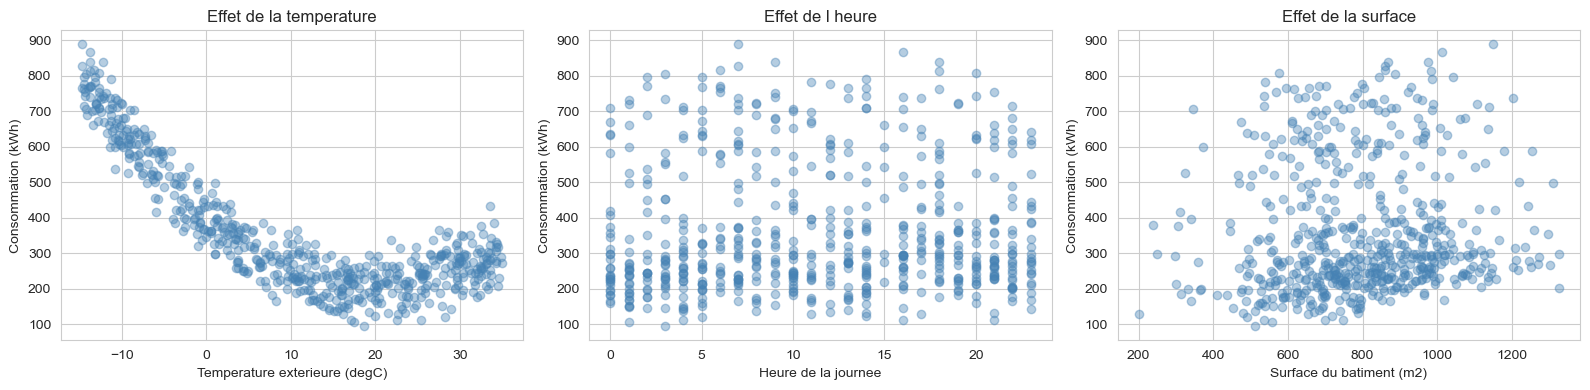

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# Effet de la temperature : on s'attend a une forme en U
axes[0].scatter(df['temperature_c'], df['consommation_kwh'], alpha=0.4, color='steelblue')
axes[0].set_xlabel('Temperature exterieure (degC)')
axes[0].set_ylabel('Consommation (kWh)')
axes[0].set_title('Effet de la temperature')

# Effet de l'heure : on s'attend a des pics
axes[1].scatter(df['heure'], df['consommation_kwh'], alpha=0.4, color='steelblue')
axes[1].set_xlabel('Heure de la journee')
axes[1].set_ylabel('Consommation (kWh)')
axes[1].set_title('Effet de l heure')

# Effet de la surface : on s'attend a une relation lineaire
axes[2].scatter(df['surface_m2'], df['consommation_kwh'], alpha=0.4, color='steelblue')
axes[2].set_xlabel('Surface du batiment (m2)')
axes[2].set_ylabel('Consommation (kWh)')
axes[2].set_title('Effet de la surface')

plt.tight_layout()
plt.show()

**Diagnostic visuel :**

- L'effet de la **temperature** est manifestement **en U** : la consommation chute vers 20 degC et remonte aux deux extremes. Une droite ne peut pas capter ca.
- L'effet de l'**heure** montre une structure complexe avec des **pics**. Pas du tout lineaire.
- L'effet de la **surface** est en revanche **lineaire**.

Un modele qui ne sait que tracer des droites va passer a cote de l'essentiel.


## 4. Preparer les donnees pour la modelisation


In [5]:
cols = ['temperature_c', 'heure', 'jour_ouvrable',
        'surface_m2', 'niveau_isolation']
X = df[cols]
y = df['consommation_kwh']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print(f'Entrainement : {X_train.shape[0]} observations')
print(f'Test         : {X_test.shape[0]} observations')

Entrainement : 480 observations
Test         : 120 observations


## 5. La regression lineaire : la baseline qui va echouer

On commence comme toujours par la regression lineaire de la seance 6. Elle servira de **reference** : tout modele plus complexe devra faire mieux qu'elle.


In [6]:
lin = LinearRegression()
lin.fit(X_train, y_train)

r2_lin = lin.score(X_test, y_test)
rmse_lin = np.sqrt(mean_squared_error(y_test, lin.predict(X_test)))

print(f'Regression lineaire :')
print(f'  R2 test   = {r2_lin:.4f}')
print(f'  RMSE test = {rmse_lin:.2f} kWh')

Regression lineaire :
  R2 test   = 0.7166
  RMSE test = 106.00 kWh


**Diagnostic.** Le R2 est d'environ **0,72** et le RMSE depasse les **100 kWh**. C'est mediocre : le modele explique seulement 72 % de la variance, et son erreur typique est tres elevee.

**Pourquoi ?** Parce que le modele lineaire **traite la temperature comme un effet monotone** (consommer plus quand il fait chaud OU consommer plus quand il fait froid -- il faut choisir). Il ne peut pas modeliser le U. Pareil pour l'heure : il prend une pente moyenne au lieu des pics.


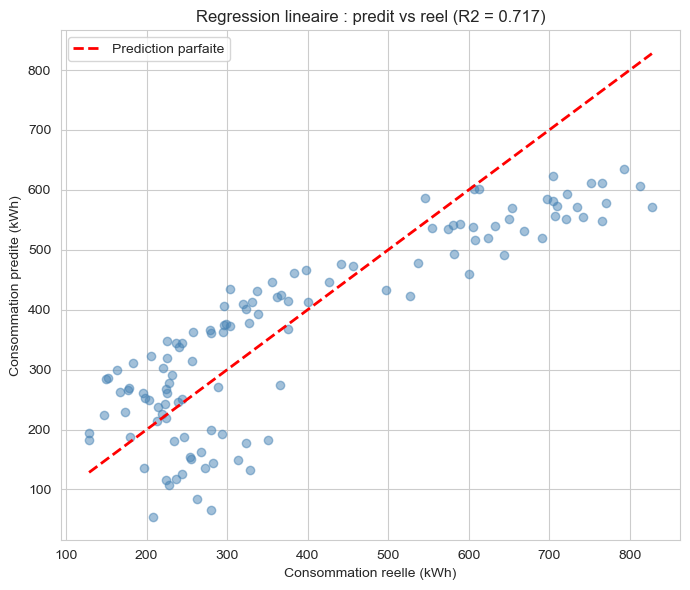

In [7]:
# Visualiser l'echec : predit vs reel
y_pred_lin = lin.predict(X_test)
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred_lin, alpha=0.5, color='steelblue')
lim = [y_test.min(), y_test.max()]
plt.plot(lim, lim, 'r--', linewidth=2, label='Prediction parfaite')
plt.xlabel('Consommation reelle (kWh)')
plt.ylabel('Consommation predite (kWh)')
plt.title(f'Regression lineaire : predit vs reel (R2 = {r2_lin:.3f})')
plt.legend()
plt.tight_layout()
plt.show()

Les points sont **dispersés** autour de la diagonale rouge -- ils ne s'alignent pas dessus. C'est le signe d'un modele insuffisant.


## 6. L'arbre de decision : capter le non-lineaire

L'arbre, lui, peut decouper la temperature en zones (« si T < 5 alors... sinon si T > 28 alors... »). C'est exactement ce qu'il faut pour un effet en U.


In [8]:
arbre = DecisionTreeRegressor(max_depth=6, random_state=42)
arbre.fit(X_train, y_train)

r2_arb = arbre.score(X_test, y_test)
rmse_arb = np.sqrt(mean_squared_error(y_test, arbre.predict(X_test)))

print(f'Arbre de decision (profondeur 6) :')
print(f'  R2 test   = {r2_arb:.4f}')
print(f'  RMSE test = {rmse_arb:.2f} kWh')

Arbre de decision (profondeur 6) :
  R2 test   = 0.9351
  RMSE test = 50.74 kWh


**Resultat.** Le R2 saute a environ **0,94** (contre 0,72 pour le lineaire) et le RMSE chute de moitie. L'arbre a capture les non-linearites que la regression lineaire ne pouvait pas voir.

Visualisons une partie de l'arbre :


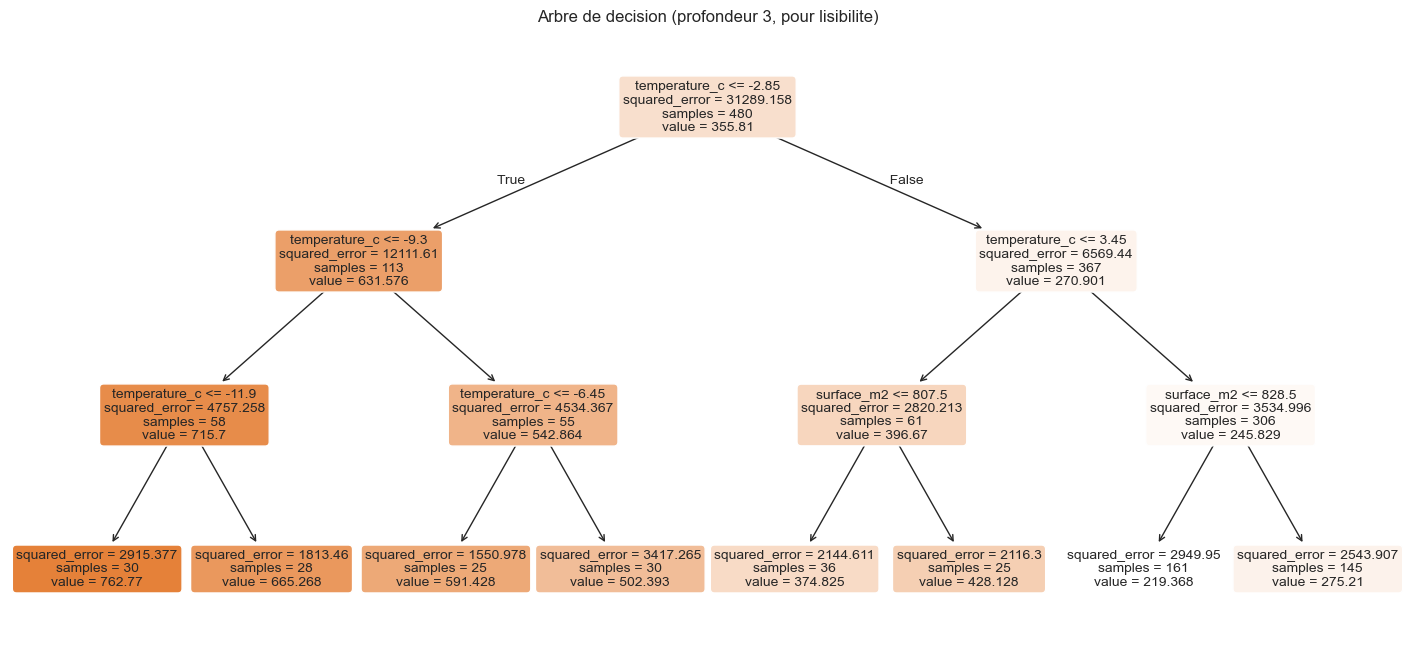

In [9]:
# On affiche un arbre limite a profondeur 3 pour rester lisible
arbre_lisible = DecisionTreeRegressor(max_depth=3, random_state=42)
arbre_lisible.fit(X_train, y_train)

plt.figure(figsize=(18, 8))
plot_tree(arbre_lisible, feature_names=cols, filled=True,
          rounded=True, fontsize=10)
plt.title('Arbre de decision (profondeur 3, pour lisibilite)')
plt.show()

Chaque noeud pose une question simple. On voit que l'arbre utilise spontanement la **temperature** et l'**heure** comme variables principales -- exactement les variables non-lineaires. Il decoupe la temperature en plages et applique une moyenne differente dans chaque plage : c'est ainsi qu'il modelise la courbe en U.


## 7. La foret aleatoire : combiner plusieurs arbres

Un arbre seul peut etre instable. La **foret aleatoire** entraine 200 arbres differents (chacun sur un sous-echantillon) et moyenne leurs predictions. Cette moyenne reduit la variance et ameliore la generalisation.


In [10]:
foret = RandomForestRegressor(n_estimators=200, random_state=42)
foret.fit(X_train, y_train)

r2_rf = foret.score(X_test, y_test)
rmse_rf = np.sqrt(mean_squared_error(y_test, foret.predict(X_test)))

print(f'Random Forest (200 arbres) :')
print(f'  R2 test   = {r2_rf:.4f}')
print(f'  RMSE test = {rmse_rf:.2f} kWh')

Random Forest (200 arbres) :
  R2 test   = 0.9591
  RMSE test = 40.27 kWh


Le R2 monte encore (autour de **0,96**) et le RMSE descend autour de **40 kWh**. La foret est meilleure que l'arbre seul parce qu'elle moyenne plusieurs decoupages differents.


## 8. Le Gradient Boosting : la performance maximale

Le Gradient Boosting construit les arbres **les uns apres les autres**, chacun corrigeant les erreurs du precedent. C'est souvent la technique la plus performante sur des donnees tabulaires.


In [11]:
gb = GradientBoostingRegressor(n_estimators=200, learning_rate=0.05,
                                max_depth=4, random_state=42)
gb.fit(X_train, y_train)

r2_gb = gb.score(X_test, y_test)
rmse_gb = np.sqrt(mean_squared_error(y_test, gb.predict(X_test)))

print(f'Gradient Boosting :')
print(f'  R2 test   = {r2_gb:.4f}')
print(f'  RMSE test = {rmse_gb:.2f} kWh')

Gradient Boosting :
  R2 test   = 0.9699
  RMSE test = 34.56 kWh


Le R2 atteint environ **0,97** : on capture presque toute la variance possible (le reste est du bruit aleatoire ajoute lors de la generation des donnees).


## 9. L'importance des variables

Quelles variables comptent le plus dans ces predictions ? La foret aleatoire le mesure automatiquement.


        variable  importance
   jour_ouvrable    0.002224
           heure    0.007687
niveau_isolation    0.023624
      surface_m2    0.036704
   temperature_c    0.929762


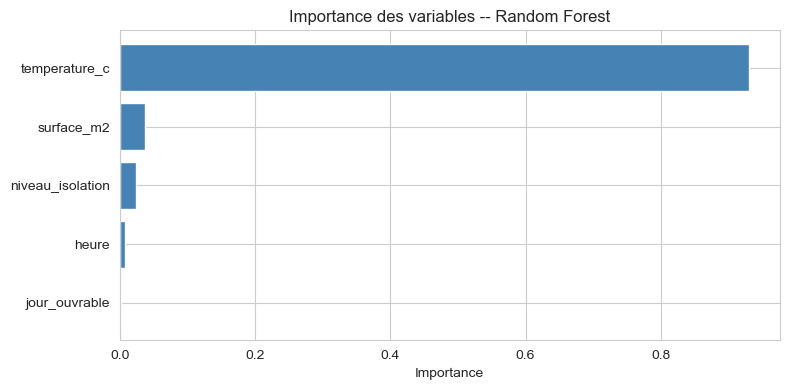

In [12]:
importances = pd.DataFrame({
    'variable': cols,
    'importance': foret.feature_importances_
}).sort_values('importance', ascending=True)

print(importances.to_string(index=False))

plt.figure(figsize=(8, 4))
plt.barh(importances['variable'], importances['importance'],
         color='steelblue', edgecolor='white')
plt.xlabel('Importance')
plt.title('Importance des variables -- Random Forest')
plt.tight_layout()
plt.show()

**Lecture.** La **temperature** est de loin la variable la plus importante (effet en U), suivie de l'**heure** (pics) et de la **surface**. Cela correspond a notre intuition physique : pour predire la consommation electrique, savoir s'il fait froid/chaud et a quelle heure on est compte plus que tout le reste.


## 10. Comparaison finale des quatre modeles


In [13]:
modeles = {
    'Regression lineaire': lin,
    'Arbre (profondeur 6)': arbre,
    'Random Forest (200 arbres)': foret,
    'Gradient Boosting': gb
}

resultats = []
for nom, m in modeles.items():
    r2 = m.score(X_test, y_test)
    rmse = np.sqrt(mean_squared_error(y_test, m.predict(X_test)))
    resultats.append({'Modele': nom, 'R2 test': r2, 'RMSE test': rmse})

comparaison = pd.DataFrame(resultats)
print(comparaison.to_string(index=False))

                    Modele  R2 test  RMSE test
       Regression lineaire 0.716611 105.995986
      Arbre (profondeur 6) 0.935060  50.740434
Random Forest (200 arbres) 0.959087  40.274452
         Gradient Boosting 0.969881  34.555849


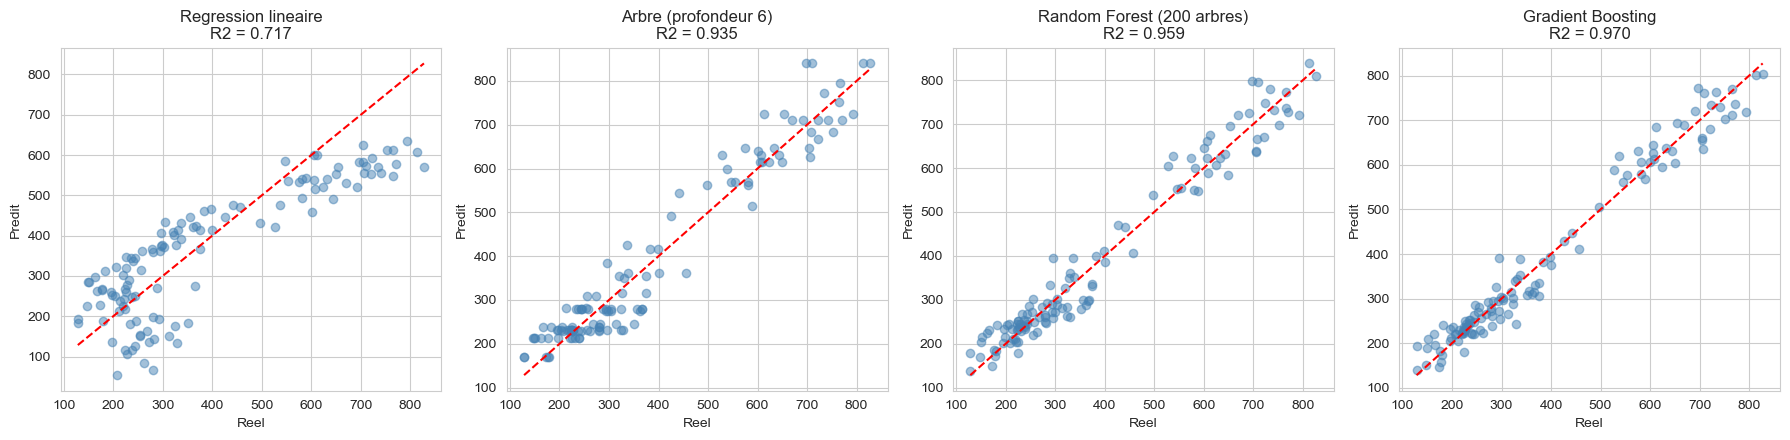

In [14]:
# Visualisation comparative
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
lim = [y_test.min(), y_test.max()]
for ax, (nom, m) in zip(axes, modeles.items()):
    y_pred = m.predict(X_test)
    r2 = m.score(X_test, y_test)
    ax.scatter(y_test, y_pred, alpha=0.5, color='steelblue')
    ax.plot(lim, lim, 'r--', linewidth=1.5)
    ax.set_xlabel('Reel')
    ax.set_ylabel('Predit')
    ax.set_title(f'{nom}\nR2 = {r2:.3f}')
plt.tight_layout()
plt.show()

**Lecture des graphiques.** Sur le premier (regression lineaire), les points sont dispersés autour de la diagonale -- le modele se trompe beaucoup. Sur les trois autres, les points s'alignent de plus en plus proprement sur la diagonale, jusqu'au Gradient Boosting ou ils sont presque colles dessus.


## 11. Synthese

**Ce que ce notebook a montre :**

- La regression lineaire fonctionne bien quand les relations sont lineaires (comme dans la seance 6 sur les prix de maisons), mais **echoue** des qu'il y a des non-linearites ou des interactions.
- Un **arbre de decision** capture naturellement les non-linearites en decoupant l'espace en zones.
- La **foret aleatoire** combine plusieurs arbres et reduit la variance pour generaliser mieux.
- Le **Gradient Boosting** construit les arbres en sequence et obtient les meilleures performances sur ce type de donnees.

**Lecon principale :** il n'existe pas un meilleur modele pour tous les problemes. Sur des donnees lineaires (seance 6, maisons), la regression lineaire reste imbattable. Sur des donnees non-lineaires (ici, consommation d'energie), les modeles bases sur les arbres dominent largement. La bonne demarche est de **toujours commencer simple** (regression lineaire comme baseline), puis d'essayer des modeles plus flexibles et de **comparer sur le jeu de test**.
